# Risk-calibrated capability approval

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/FEI-JIANG/uccap/blob/main/examples/notebooks/02_risk_calibrated_approval.ipynb)

Companion notebook to F. Jiang and L. Yang, *Risk-calibrated process capability approval with finite
samples*, Int. J. Adv. Manuf. Technol. 144:7189–7206 (2026),
[doi:10.1007/s00170-026-18284-2](https://doi.org/10.1007/s00170-026-18284-2)
([arXiv:2603.14479](https://arxiv.org/abs/2603.14479)).

Approving a process when the estimated Cpk is at least 1.33 ignores that the estimate is uncertain.
The article replaces the threshold by **accept iff Ĉpk ≥ C0 + k·SE(Ĉpk)**, with k set by a tolerable
risk α or by the cost ratio λ of a false acceptance to a false rejection. This notebook shows the
rule with `uccap.risk`, plans a study, and reproduces the article's simulation results.

In [1]:
# On Colab or another fresh environment, install uccap first
try:
    import uccap
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "uccap[plot] @ git+https://github.com/FEI-JIANG/uccap"], check=True)

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import uccap
np.set_printoptions(precision=4, suppress=True)

## 1. How uncertain is an estimate from 32 parts?

Simulate many studies of the same process, true Cpk = 1.40, n = 32: the estimates spread from about
1.1 to 1.8, and a large share of them fall below 1.33 although the process is capable.

P(estimate < 1.33) = 0.41


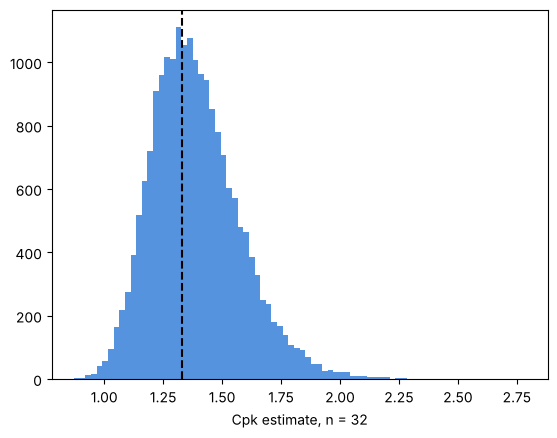

In [3]:
T, true_cpk, n = 4.0, 1.40, 32
rng = np.random.default_rng(1)
samples = rng.normal(0, T / (3 * true_cpk), (20000, n))
m, s = samples.mean(1), samples.std(1, ddof=1)
est = np.minimum(T - m, m + T) / (3 * s)
print(f"P(estimate < 1.33) = {np.mean(est < 1.33):.2f}")
plt.hist(est, bins=80, color="#2a78d6", alpha=.8)
plt.axvline(1.33, color="k", ls="--"); plt.xlabel("Cpk estimate, n = 32"); plt.show()

## 2. The risk-calibrated rule

`risk_decision` computes SE = √((1/9 + Ĉ²/2)/n), the probability that the true capability is below
C0, and the decision. Here a false acceptance is taken to cost 19 times a false rejection
(λ = 19, α = 0.05).

In [4]:
x = np.random.default_rng(42).normal(loc=4.625, scale=0.023, size=32)
study = uccap.capability_study(x, lsl=4.52, usl=4.72, target=4.62)
decision = uccap.risk_decision(study, c0=1.33, cost_ratio=19)
print(decision.report())

  RISK-CALIBRATED APPROVAL
         Requirement : Ppk >= C0 = 1.33
          Risk basis : cost ratio c_FA/c_FR = 19  ->  alpha = 0.050
----------------------------------------------------------------
        Ppk estimate : 1.603
      Standard error : 0.209
        P(true < C0) : 0.096   (analytic)
   Required estimate : 1.674   (C0 + 1.645 x SE at this estimate)
   Smallest accepted : 1.691   (estimate that just passes with n = 32)
----------------------------------------------------------------
      Threshold rule : ACCEPT  (estimate >= C0)
     Risk-calibrated : REJECT  (P = 0.096 > alpha)

  Note: the two rules differ because the estimate is close to C0 for this
  sample size. C0 is unchanged; the calibrated rule shows how much evidence
  the sample gives. More parts or the actual cost ratio settle the case.


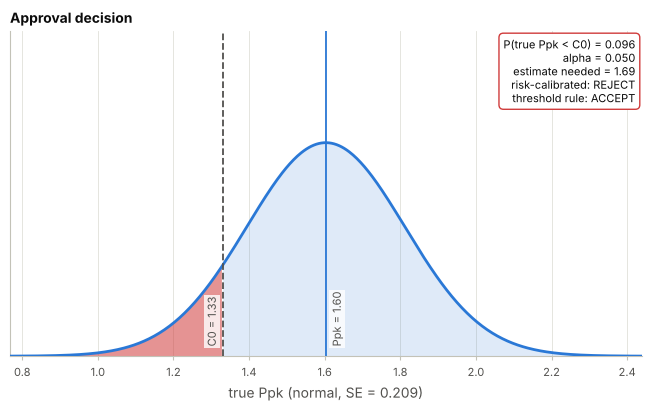

In [5]:
decision.plot(study);

Table 1 of the article: the margin k for common cost ratios.

In [6]:
from uccap.risk import k_from_cost_ratio
for lam in (1, 4, 9, 19, 99):
    print(f"lambda = {lam:>3}   alpha = {1 / (1 + lam):.2f}   k = {k_from_cost_ratio(lam):.3f}")

lambda =   1   alpha = 0.50   k = 0.000
lambda =   4   alpha = 0.20   k = 0.842
lambda =   9   alpha = 0.10   k = 1.282
lambda =  19   alpha = 0.05   k = 1.645
lambda =  99   alpha = 0.01   k = 2.326


A supplier's reported value can be judged the same way, from the estimate and the sample size alone.

In [7]:
d = uccap.risk_decision(1.45, n=32, c0=1.33, alpha=0.05)
d.accept, round(d.p_fail, 3), round(d.margin, 3)

(False, 0.264, 1.643)

## 3. Planning: how many parts?

The smallest estimate that is accepted falls with n. Before a study, `sample_size` gives the number of
parts needed so that a process with an assumed true Cpk is approved with a wanted probability.

In [8]:
from uccap.risk import min_accepted
for n in (20, 32, 50, 100, 200):
    print(f"n = {n:>3}: smallest accepted estimate {min_accepted(n, cost_ratio=19):.3f}")
print()
print(uccap.sample_size(1.67, c0=1.33, cost_ratio=19, power=0.8).report())

n =  20: smallest accepted estimate 1.819
n =  32: smallest accepted estimate 1.691
n =  50: smallest accepted estimate 1.605
n = 100: smallest accepted estimate 1.514
n = 200: smallest accepted estimate 1.456

Sample-size plan (risk-calibrated approval)
            Requirement C0  1.33
                 Risk rule  cost ratio 19 (alpha = 0.050)
          Assumed true Cpk  1.67
          Wanted P(accept)  80%
              Parts needed  80
    P(accept) with n parts  80.5%
     Smallest accepted Cpk  1.539


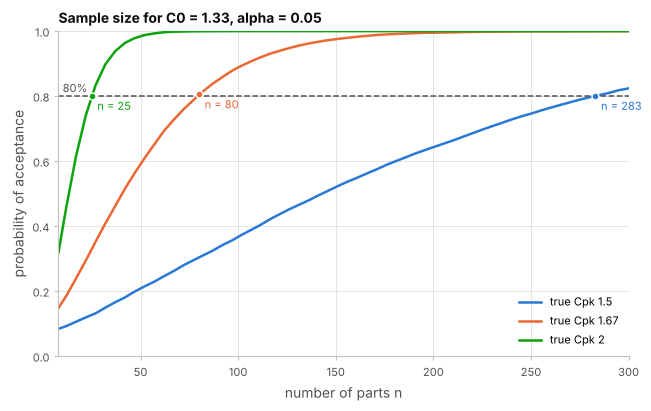

In [9]:
from uccap.plot import planning_plot
planning_plot((1.5, 1.67, 2.0), cost_ratio=19, n_range=(8, 300));

## 4. The article's simulation (Section 5)

`validation/risk_simulation.py` reproduces Table 1 and the expected-loss comparison of Table 2
(n = 32, a process just below the requirement, so every acceptance is a false acceptance costing λ).
The article used 12,000 replications; the column *diff/SE* is the difference in units of its Monte
Carlo standard error.

In [10]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1] / "validation"))
import risk_simulation
for r in risk_simulation.table2(b=200_000):
    print(f"lambda {r['lambda']:>3}:  deterministic {r['det_article']:7.3f} vs {r['det']:7.3f}   "
          f"calibrated {r['cal_article']:.3f} vs {r['cal']:.3f}   "
          f"reduction {r['reduction_article']:.1f} % vs {r['reduction']:.1f} %")

lambda   2:  deterministic   0.793 vs   0.803   calibrated 0.483 vs 0.501   reduction 39.2 % vs 37.6 %
lambda   5:  deterministic   2.037 vs   2.008   calibrated 0.565 vs 0.552   reduction 72.3 % vs 72.5 %
lambda  10:  deterministic   4.021 vs   4.016   calibrated 0.553 vs 0.540   reduction 86.3 % vs 86.6 %
lambda  20:  deterministic   8.052 vs   8.032   calibrated 0.527 vs 0.501   reduction 93.5 % vs 93.8 %
lambda  50:  deterministic  20.038 vs  20.080   calibrated 0.479 vs 0.432   reduction 97.6 % vs 97.8 %
lambda 100:  deterministic  40.567 vs  40.160   calibrated 0.375 vs 0.387   reduction 99.1 % vs 99.0 %


The risk-calibrated rule keeps the expected loss below 0.6 at every cost ratio, while the loss of
the threshold rule grows in proportion to λ.

## 5. Many dimensions

`batch_study` applies the same decision to every dimension of a file; `reversed` marks dimensions where
the two rules disagree.

In [11]:
rng = np.random.default_rng(10)
import pandas as pd
data = pd.DataFrame({f"D{i}": rng.normal(10, sd, 32) for i, sd in enumerate((0.0167, 0.019, 0.023, 0.024, 0.03), 1)})
specs = {d: {"lsl": 9.9, "usl": 10.1, "target": 10.0} for d in data}
res = uccap.batch_study(data, specs, c0=1.33, cost_ratio=19)
res.table(["dimension", "Ppk", "p_fail", "required", "threshold_decision", "decision", "reversed"]).round(3)

,dimension,Ppk,p_fail,required,threshold_decision,decision,reversed
0,D1,2.285,0.000,1.810,ACCEPT,ACCEPT,False
1,D2,2.109,0.002,1.774,ACCEPT,ACCEPT,False
2,D3,1.639,0.074,1.681,ACCEPT,REJECT,True
3,D4,1.322,0.519,1.618,REJECT,REJECT,False
4,D5,1.016,0.988,1.560,REJECT,REJECT,False


D3 has Ppk = 1.64, comfortably above 1.33 by the threshold rule, but with 32 parts the evidence is
not strong enough at λ = 19: the risk-calibrated rule reverses the decision.

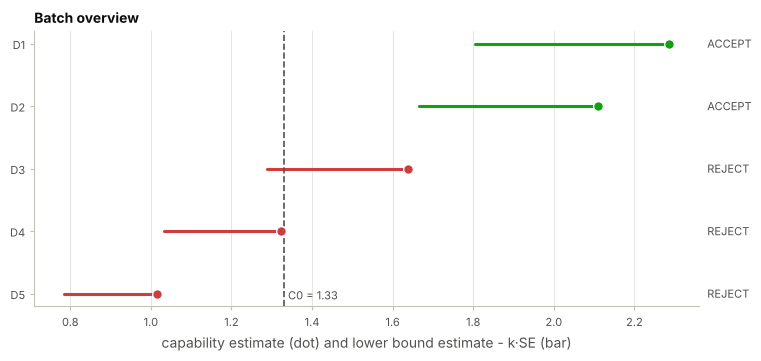

In [12]:
res.plot();